# Case study: segments, maps and implausible listings among Berlin's Airbnb offers

*Session 11, worked example of block 1 (part A) and block 2 (parts B and C). Author: course team, licence CC-BY-4.0. Data: Inside Airbnb, Berlin, snapshot of 26 June 2026 (CC BY 4.0).*

**Questions.** What kinds of Airbnb offers exist in Berlin? Where are they concentrated? What do the listings offer, and which listings are implausible? A city office that enforces the rules on short-term rentals, a tourism board or a new host would ask these questions; none of them comes with a target variable.

- **Part A (block 1):** k-means, hierarchical clustering and DBSCAN on six numbers per listing; evaluate with silhouette, stability and profiles; describe the clusters by district and room type, which the clustering did not see. DBSCAN on the map finds hot spots of listings.
- **Part B (block 2):** PCA of the amenity lists and a t-SNE map of the listings.
- **Part C (block 2):** implausible listings with Isolation Forest, LOF and a price ratio; do location clusters improve a gradient-boosting price model (Session 10)?

Theory: [lecture of block 1](01-lecture-clustering.ipynb), [lecture of block 2](04-lecture-dimensionality-reduction-and-anomaly-detection.ipynb). Prepare the data once with `uv run python case-study/prepare_airbnb.py`.

*Ethics:* the data are scraped from public listing pages. Report in aggregate; do not name hosts, and do not publish lists of single listings outside the course.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn.cluster import DBSCAN, KMeans
from sklearn.compose import make_column_transformer
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingRegressor, IsolationForest
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.model_selection import GroupKFold, KFold, cross_val_predict, cross_val_score
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MultiLabelBinarizer, OrdinalEncoder, StandardScaler

pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 14)
# find the repository root, wherever the notebook is started from
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "case-study" / "data").exists())
DATA = ROOT / "case-study" / "data"

listings = pd.read_parquet(DATA / "airbnb" / "listings.parquet")
lat0, lon0 = 52.5219, 13.4132                                   # Alexanderplatz
listings["north_km"] = (listings["latitude"] - lat0) * 111.2
listings["east_km"] = (listings["longitude"] - lon0) * 111.2 * np.cos(np.radians(lat0))
listings["km_centre"] = np.hypot(listings["north_km"], listings["east_km"])
print(len(listings), "listings;", round(listings["price"].isna().mean(), 2), "without a price")

12776 listings; 0.34 without a price


# Part A: what kinds of offers exist?

## A.1 Six numbers per listing

In [2]:
d = listings.dropna(subset=["price", "minimum_nights"]).reset_index(drop=True)
features = pd.DataFrame({
    "log_price": np.log(d["price"]), "guests": d["accommodates"],
    "log_min_nights": np.log(d["minimum_nights"]), "availability_365": d["availability_365"],
    "log_reviews_ltm": np.log1p(d["number_of_reviews_ltm"]), "km_centre": d["km_centre"],
})
Z = StandardScaler().fit_transform(features)
features.describe().round(2)

,log_price,guests,log_min_nights,availability_365,log_reviews_ltm,km_centre
count,8439.00,8439.0,8439.00,8439.00,8439.00,8439.00
mean,4.69,3.4,1.35,215.49,1.83,5.27
std,0.96,2.2,1.68,115.82,1.46,3.95
min,1.00,1.0,0.00,1.00,0.00,0.17
25%,4.28,2.0,0.00,116.00,0.00,2.61
50%,4.87,3.0,0.69,242.00,1.95,4.18
75%,5.33,4.0,1.79,321.00,3.14,6.83
max,9.21,16.0,5.90,365.00,6.03,25.61


**Question.** Why are price, minimum nights and reviews log-transformed before standardising? Plot a histogram of `d["minimum_nights"]` (log scale): which values stand out?

## A.2 k-means for several k

In [3]:
rows = []
for k in range(2, 9):
    km_k = KMeans(k, n_init=10, random_state=0).fit(Z)
    rows.append({"k": k, "inertia": km_k.inertia_, "silhouette": silhouette_score(Z, km_k.labels_, sample_size=5000, random_state=0)})
pd.DataFrame(rows).set_index("k").round(3)

,inertia,silhouette
k,,
2,34417.418,0.363
3,28457.383,0.266
4,24083.500,0.276
5,20416.688,0.290
6,18286.419,0.280
7,17186.646,0.258
8,16191.534,0.256


## A.3 Hierarchical clustering (Ward) on a sample

silhouette on the sample: k-means 0.302 | Ward 0.257 | ARI between them 0.65


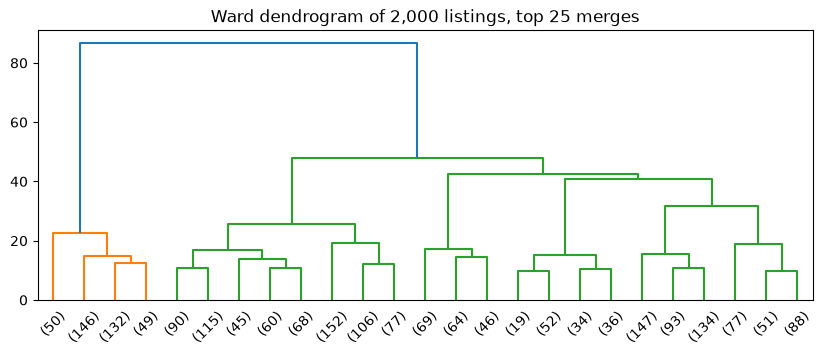

In [4]:
rng = np.random.default_rng(0)
idx = rng.choice(len(Z), size=2000, replace=False)
Z_ward = linkage(Z[idx], method="ward")
fig, ax = plt.subplots(figsize=(10, 3.5))
dendrogram(Z_ward, truncate_mode="lastp", p=25, ax=ax)
ax.set_title("Ward dendrogram of 2,000 listings, top 25 merges")
ward5 = fcluster(Z_ward, t=5, criterion="maxclust")
km = KMeans(5, n_init=10, random_state=0).fit(Z)
print("silhouette on the sample: k-means", round(silhouette_score(Z[idx], km.labels_[idx]), 3),
      "| Ward", round(silhouette_score(Z[idx], ward5), 3),
      "| ARI between them", round(adjusted_rand_score(km.labels_[idx], ward5), 2))

## A.4 DBSCAN on the features and on the map

In [5]:
dist, _ = NearestNeighbors(n_neighbors=10).fit(Z).kneighbors(Z)
print("10th-neighbour distance quantiles:", np.quantile(dist[:, -1], [0.5, 0.9, 0.99]).round(2))
for eps in (0.5, 0.8, 1.0):
    labels = pd.Series(DBSCAN(eps=eps, min_samples=10).fit_predict(Z))
    print(eps, labels.nunique() - (labels == -1).any(), "clusters,", (labels == -1).sum(), "noise")

10th-neighbour distance quantiles: [0.57 0.91 1.46]
0.5 11 clusters, 4091 noise


0.8 3 clusters, 625 noise


1.0 1 clusters, 229 noise


,listings,area,median_price
hot_spot,,,
0,1703,Alexanderplatz,170.500
1,789,südliche Luisenstadt,129.000
2,585,Frankfurter Allee Süd FK,139.800
9,266,Alexanderplatz,140.000
5,246,Düsseldorfer Straße,128.000
12,218,Tempelhofer Vorstadt,140.665
11,186,Brunnenstr. Nord,155.285
6,146,Kurfürstendamm,128.625


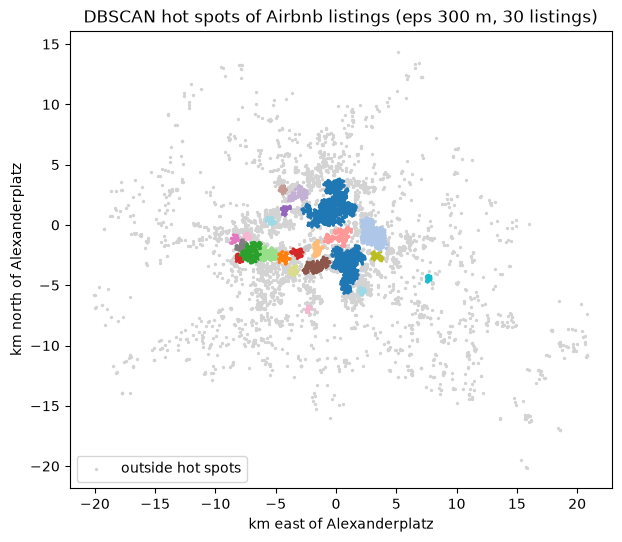

In [6]:
C = d[["east_km", "north_km"]].to_numpy()
d["hot_spot"] = DBSCAN(eps=0.3, min_samples=30).fit_predict(C)
fig, ax = plt.subplots(figsize=(7, 6))
out = d["hot_spot"] == -1
ax.scatter(d.loc[out, "east_km"], d.loc[out, "north_km"], s=2, color="lightgrey", label="outside hot spots")
ax.scatter(d.loc[~out, "east_km"], d.loc[~out, "north_km"], s=2, c=d.loc[~out, "hot_spot"], cmap="tab20")
ax.set(xlabel="km east of Alexanderplatz", ylabel="km north of Alexanderplatz", aspect="equal",
       title="DBSCAN hot spots of Airbnb listings (eps 300 m, 30 listings)")
ax.legend(loc="lower left")
(d[~out].groupby("hot_spot").agg(listings=("id", "size"), area=("neighbourhood", lambda s: s.mode()[0]),
                                  median_price=("price", "median")).nlargest(8, "listings"))

## A.5 Stability and profile of the chosen clustering

In [7]:
aris = []
for seed in range(10):
    boot = rng.choice(len(Z), size=len(Z), replace=True)
    aris.append(adjusted_rand_score(km.labels_, KMeans(5, n_init=10, random_state=seed).fit(Z[boot]).predict(Z)))
print("bootstrap ARI min / median:", np.round([min(aris), np.median(aris)], 2))
d["cluster"] = km.labels_
d.groupby("cluster").agg(
    listings=("id", "size"), price=("price", "median"), guests=("accommodates", "median"),
    min_nights=("minimum_nights", "median"), open_days=("availability_365", "median"),
    reviews_ltm=("number_of_reviews_ltm", "median"), km_centre=("km_centre", "median"),
    entire_home=("room_type", lambda s: (s == "Entire home/apt").mean()),
    multi_host=("calculated_host_listings_count", lambda s: (s > 1).mean()),
    licence_given=("license", lambda s: s.notna().mean()),
).round(2)

bootstrap ARI min / median: [0.96 0.98]


,listings,price,guests,min_nights,open_days,reviews_ltm,km_centre,entire_home,multi_host,licence_given
cluster,,,,,,,,,,
0,2514,153.00,2.0,1.0,307.0,15.0,3.62,0.68,0.70,0.98
1,2412,136.55,2.0,2.0,63.0,8.0,4.01,0.64,0.41,0.99
2,1698,22.84,2.0,92.0,275.0,0.0,4.33,0.82,0.52,0.20
3,1037,293.00,7.0,1.0,273.0,18.0,3.72,0.95,0.81,0.99
4,778,119.10,3.0,2.0,257.0,4.0,13.61,0.65,0.46,0.95


In [8]:
pd.crosstab(d["district"], d["cluster"], normalize="index").round(2)

cluster,0,1,2,3,4
district,,,,,
Charlottenburg-Wilm.,0.32,0.26,0.26,0.09,0.06
Friedrichshain-Kreuzberg,0.34,0.33,0.19,0.13,0.00
Lichtenberg,0.35,0.35,0.12,0.11,0.08
Marzahn - Hellersdorf,0.04,0.09,0.24,0.08,0.55
Mitte,0.34,0.27,0.23,0.16,0.00
Neukölln,0.22,0.42,0.18,0.09,0.10
Pankow,0.37,0.29,0.17,0.16,0.02
Reinickendorf,0.19,0.14,0.26,0.00,0.41
Spandau,0.00,0.00,0.10,0.01,0.89


**Exercise A.** Write a one-paragraph description of the five clusters for a city official: one sentence per cluster, its size, and the evidence (variables not used in the clustering: room type, district, host with several listings, registration number given). How stable is the segmentation, and how well separated? Which cluster shows a data problem in the price column?

# Part B: what do the listings offer?

## B.1 PCA of the amenity lists

In [9]:
mlb = MultiLabelBinarizer()
A = pd.DataFrame(mlb.fit_transform(listings["amenities"].apply(json.loads)), columns=mlb.classes_, index=listings.index)
share = A.mean()
A = A.loc[:, (share >= 0.05) & (share <= 0.95)]
pca_a = PCA().fit(A)
print(len(mlb.classes_), "labels;", A.shape[1], "kept; variance of PC1-PC3:", pca_a.explained_variance_ratio_[:3].round(3))
loadings = pd.DataFrame(pca_a.components_[:3].T, index=A.columns, columns=["PC1", "PC2", "PC3"])
pd.concat({pc: loadings[pc].sort_values(ascending=False).head(5).index.to_series(index=range(5))
           for pc in loadings} | {f"{pc} (negative)": loadings[pc].sort_values().head(5).index.to_series(index=range(5))
                                  for pc in loadings}, axis=1)

2653 labels; 90 kept; variance of PC1-PC3: [0.212 0.058 0.046]


,PC1,PC2,PC3,PC1 (negative),PC2 (negative),PC3 (negative)
0,Hot water kettle,Heating,Washer,Washer,Central heating,Self check-in
1,Dining table,Stove,Oven,Wifi,Cleaning products,Fire extinguisher
2,Cooking basics,Coffee maker,Dishwasher,Smoking allowed,Drying rack for clothing,Shampoo
3,Wine glasses,Oven,Stove,Heating,Dining table,Shower gel
4,Dishes and silverware,Refrigerator,Kitchen,Free parking on premises,Wine glasses,Luggage dropoff allowed


**Questions.** (a) What does PC1 measure? Correlate its scores with the number of amenities per listing. (b) Look at PC2: `pd.crosstab(A["Heating"], A["Central heating"])`. Is PC2 about the flats, or about how the amenity form was filled in? (c) Name PC3 from its loadings, then check your name against the room types.

## B.2 A t-SNE map of the listings (amenities, 20 components)

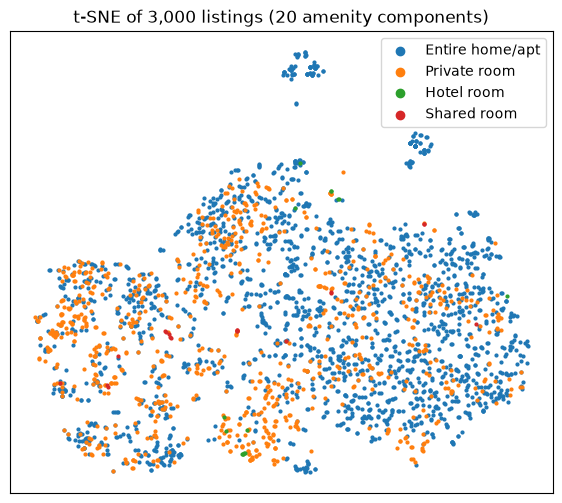

In [10]:
pick = np.random.default_rng(1).choice(len(A), size=3000, replace=False)
S = pca_a.transform(A)[pick, :20]
emb = TSNE(perplexity=30, init="pca", random_state=0).fit_transform(S)
rooms = listings["room_type"].to_numpy()[pick]
fig, ax = plt.subplots(figsize=(7, 6))
for room in ["Entire home/apt", "Private room", "Hotel room", "Shared room"]:
    m = rooms == room
    ax.scatter(*emb[m].T, s=4, label=room)
ax.set(title="t-SNE of 3,000 listings (20 amenity components)", xticks=[], yticks=[])
ax.legend(markerscale=3)

**Question.** Which groups do you see, and which variable explains them? What may you *not* conclude from the distances between the groups (lecture of block 2)?

# Part C: implausible listings and cluster features

## C.1 Isolation Forest, LOF and the price ratio

Short stays only (minimum below 90 nights): the medium-term rentals have a different kind of price.

In [11]:
short = listings[listings["price"].notna() & (listings["minimum_nights"] < 90)].reset_index(drop=True)
short["log_price"] = np.log(short["price"])
short["log_min_nights"] = np.log(short["minimum_nights"])
Zs = StandardScaler().fit_transform(short[["log_price", "accommodates", "log_min_nights", "km_centre"]])
short["iso"] = -IsolationForest(random_state=0).fit(Zs).score_samples(Zs)
short["lof"] = -LocalOutlierFactor(n_neighbors=20).fit(Zs).negative_outlier_factor_
X = pd.get_dummies(short[["accommodates", "bedrooms", "east_km", "north_km", "room_type"]], dtype=float)
expected = cross_val_predict(HistGradientBoostingRegressor(random_state=0), X, short["log_price"],
                             cv=KFold(5, shuffle=True, random_state=0))
short["ratio"] = np.exp(short["log_price"] - expected)
show = ["room_type", "property_type", "accommodates", "bedrooms", "price", "minimum_nights", "km_centre", "number_of_reviews"]
print(len(short), "short-stay listings;", ((short["ratio"] > 3) | (short["ratio"] < 1 / 3)).sum(), "off by a factor of 3 or more")
short.nlargest(8, "ratio")[show + ["ratio", "iso", "lof"]].round(2)

6924 short-stay listings; 110 off by a factor of 3 or more


,room_type,property_type,accommodates,bedrooms,price,minimum_nights,km_centre,number_of_reviews,ratio,iso,lof
6858,Entire home/apt,Entire home,5,2.0,7999.20,1.0,15.60,0,40.79,0.64,2.37
4024,Entire home/apt,Entire loft,7,2.0,10025.00,2.0,14.50,68,34.32,0.64,2.48
5406,Entire home/apt,Entire home,2,1.0,950.00,1.0,9.64,11,9.66,0.55,1.49
1429,Private room,Private room in rental unit,2,NaN,953.33,3.0,2.47,67,8.86,0.54,1.65
136,Entire home/apt,Entire loft,2,1.0,861.00,1.0,4.01,38,7.94,0.52,1.43
6854,Entire home/apt,Entire rental unit,2,1.0,1040.00,1.0,7.32,0,7.55,0.53,1.46
3941,Entire home/apt,Entire rental unit,2,1.0,1000.00,2.0,10.78,14,7.50,0.56,1.55
5127,Entire home/apt,Entire rental unit,1,1.0,759.57,1.0,8.85,0,7.22,0.56,1.42


In [12]:
short.nsmallest(8, "ratio")[show + ["ratio", "iso", "lof"]].round(2)

,room_type,property_type,accommodates,bedrooms,price,minimum_nights,km_centre,number_of_reviews,ratio,iso,lof
95,Entire home/apt,Entire rental unit,2,1.0,14.68,1.0,2.94,51,0.09,0.54,1.52
70,Private room,Private room in rental unit,2,NaN,9.03,25.0,3.59,310,0.09,0.64,1.45
1858,Entire home/apt,Entire rental unit,2,1.0,18.85,2.0,4.38,24,0.10,0.53,1.38
371,Entire home/apt,Entire rental unit,2,1.0,14.80,28.0,2.41,152,0.10,0.65,1.73
3080,Entire home/apt,Entire condo,3,2.0,22.07,3.0,3.43,13,0.11,0.54,1.50
3556,Entire home/apt,Entire rental unit,4,1.0,26.57,84.0,0.48,30,0.12,0.70,2.15
1021,Private room,Private room in rental unit,1,NaN,10.47,23.0,2.20,8,0.12,0.67,1.69
3835,Entire home/apt,Entire rental unit,3,1.0,21.84,56.0,4.36,1,0.14,0.66,1.40


In [13]:
short.nlargest(8, "iso")[show + ["ratio", "iso", "lof"]].round(2)

,room_type,property_type,accommodates,bedrooms,price,minimum_nights,km_centre,number_of_reviews,ratio,iso,lof
4689,Entire home/apt,Houseboat,16,1.0,4458.00,1.0,22.45,1,3.57,0.75,2.39
5497,Entire home/apt,Entire home,16,12.0,2296.00,1.0,21.07,1,2.96,0.74,2.52
5826,Entire home/apt,Houseboat,12,1.0,2270.40,1.0,22.43,2,4.17,0.72,2.27
2935,Entire home/apt,Houseboat,12,3.0,1825.00,1.0,22.45,9,2.46,0.72,2.31
731,Private room,Private room in rental unit,1,NaN,14.09,85.0,13.34,35,0.17,0.72,2.03
4683,Entire home/apt,Houseboat,6,2.0,1189.29,7.0,22.39,0,4.31,0.70,2.30
3556,Entire home/apt,Entire rental unit,4,1.0,26.57,84.0,0.48,30,0.12,0.70,2.15
2420,Entire home/apt,Houseboat,12,3.0,2100.00,1.0,16.12,15,4.82,0.69,2.36


**Exercise C.1.** For the top eight of each list decide: probably an error or placeholder, probably genuine but rare, or unclear? What would a person need to check on the listing page? How many listings per week could a city office check, and what threshold for the ratio would that imply?

## C.2 Do location clusters improve the price model?

Gradient boosting for the log price (as in Session 10), folds grouped by host. Three variants: district only, plus distances to 20 k-means location clusters (fitted inside each fold), plus raw coordinates.

In [14]:
def price_model(location=None, k=20):
    parts = [(OrdinalEncoder(), ["room_type", "district"]),
             ("passthrough", ["accommodates", "bedrooms", "minimum_nights"])]
    if location == "clusters":
        parts.append((KMeans(n_clusters=k, n_init=10, random_state=0), ["east_km", "north_km"]))
    if location == "coordinates":
        parts.append(("passthrough", ["east_km", "north_km"]))
    return make_pipeline(make_column_transformer(*parts),
                         HistGradientBoostingRegressor(categorical_features=[0, 1], random_state=0))


rows = []
for name, location in [("district only", None), ("+ 20 location clusters", "clusters"), ("+ raw coordinates", "coordinates")]:
    mae = -cross_val_score(price_model(location), short, short["log_price"], groups=short["host_id"],
                           cv=GroupKFold(n_splits=5), scoring="neg_mean_absolute_error")
    rows.append({"features": name, "MAE (log)": mae.mean(), "sd across folds": mae.std(),
                 "typical factor off": np.exp(mae.mean())})
pd.DataFrame(rows).set_index("features").round(3)

,MAE (log),sd across folds,typical factor off
features,,,
district only,0.299,0.008,1.348
+ 20 location clusters,0.291,0.009,1.338
+ raw coordinates,0.289,0.010,1.336


**Questions.** (1) Is the gain from location clusters larger than the spread across folds? (2) Why do raw coordinates work as well for a tree? (3) Repeat with a linear model (`Ridge` after one-hot encoding) instead of gradient boosting: do the clusters help more there? (4) Why must k-means be fitted inside the pipeline?

## Exercises

The exercises on this case study are in [session-11-exercises.ipynb](session-11-exercises.ipynb), part 1 and part 2.